# 01 · EDA — Olist reviews

How many reviews have text, score distribution, text length and random examples per score. Cleaning logic lives in `review_distill.data`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from review_distill.data import add_text_column, load_raw_reviews, prepare_reviews

SEED = 42
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

raw = load_raw_reviews()
raw.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01 00:00:00,2018-03-02 10:26:53


## How many reviews have text?

In [2]:
raw = add_text_column(raw)
clean = prepare_reviews(raw)
has_text = raw[raw.text != ""]
funnel = pd.Series(
    {
        "rows": len(raw),
        "unique review_id": raw.review_id.nunique(),
        "with title": raw.review_comment_title.notna().sum(),
        "with message": raw.review_comment_message.notna().sum(),
        "with any text": len(has_text),
        "with text, unique review_id": has_text.review_id.nunique(),
        "clean (unique id and text)": len(clean),
    }
)
funnel.to_frame("n").assign(pct_of_rows=lambda d: (100 * d.n / len(raw)).round(1))

,n,pct_of_rows
rows,99224,100.0
unique review_id,98410,99.2
with title,11568,11.7
with message,40977,41.3
with any text,42687,43.0
"with text, unique review_id",42370,42.7
clean (unique id and text),36469,36.8


## Score distribution

In [3]:
dist = pd.DataFrame(
    {
        "all": raw.review_score.value_counts().sort_index(),
        "clean_with_text": clean.score.value_counts().sort_index(),
    }
)
dist["pct_all"] = (100 * dist["all"] / dist["all"].sum()).round(1)
dist["pct_clean"] = (100 * dist.clean_with_text / dist.clean_with_text.sum()).round(1)
dist["pct_with_text"] = (100 * has_text.review_score.value_counts() / dist["all"]).round(1)
dist

,all,clean_with_text,pct_all,pct_clean,pct_with_text
1,11424,8371,11.5,23.0,77.3
2,3151,2059,3.2,5.6,68.7
3,8179,3264,8.2,9.0,44.5
4,19142,5143,19.3,14.1,32.8
5,57328,17632,57.8,48.3,38.0


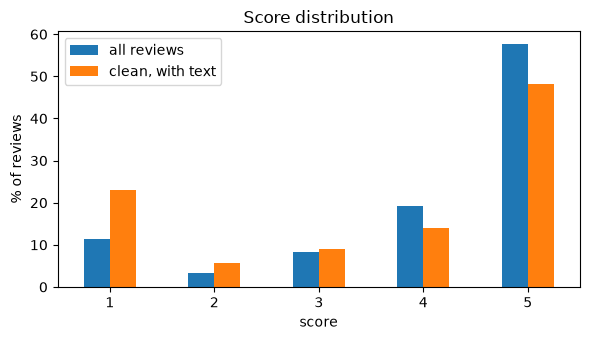

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
dist[["pct_all", "pct_clean"]].plot.bar(ax=ax, rot=0)
ax.set(xlabel="score", ylabel="% of reviews", title="Score distribution")
ax.legend(["all reviews", "clean, with text"])
plt.tight_layout()

## Text length (clean set)

In [5]:
clean = clean.assign(chars=clean.text.str.len(), words=clean.text.str.split().str.len())
clean[["chars", "words"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1)

,chars,words
count,36469.0,36469.0
mean,78.4,13.3
std,53.5,9.5
min,1.0,1.0
5%,17.0,3.0
25%,38.0,6.0
50%,62.0,10.0
75%,106.0,18.0
95%,195.0,34.0
99%,212.0,38.0


In [6]:
clean.groupby("score").words.describe(percentiles=[0.5, 0.95]).round(1)

,count,mean,std,min,50%,95%,max
score,,,,,,,
1,8371.0,18.5,10.5,1.0,17.0,36.0,46.0
2,2059.0,18.1,10.5,1.0,17.0,36.0,43.0
3,3264.0,16.2,10.2,1.0,14.0,36.0,45.0
4,5143.0,12.4,9.2,1.0,10.0,33.0,45.0
5,17632.0,10.0,7.1,1.0,8.0,26.0,48.0


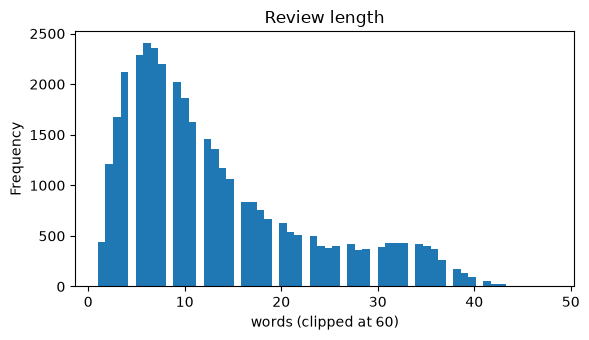

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
clean.words.clip(upper=60).plot.hist(bins=60, ax=ax)
ax.set(xlabel="words (clipped at 60)", title="Review length")
plt.tight_layout()

## 20 random examples per score

In [8]:
clean[clean.score == 1].sample(20, random_state=SEED)[["review_id", "text"]].reset_index(drop=True)

,review_id,text
0,c48adb66e492dba2511d13d6007f18a8,"Recebi o produto diferente do que estava na oferta, já solicitei o reembolso do meu valor e até agora não obtive nenhuma resposta para solução."
1,e775c41a3df4e0792c5802b7c2b12231,"O prazo de entrega foi estipula para 19 de julho a compra foi feita em 26 de junho e ainda não foi entregue, ou seja razo de entrega não foi cumprido conforme anunciado no site na hora da compra."
2,cb80085b80dc764d150fa6451fb59c0b,"Entrega nao foi feita, e tive grande dificuldade para obter uma explicavao e tentar resolver. Ate agora ainda nao esta resolvido."
3,dd6f86cbb7d481b9422f703a1735de4b,Cade o produto que comprei?
4,2c5d7f9d3ebb311f84368aca454e270a,"nao recebi o produto suporte de cone, recebi um totalmente errado todo quebrado . quero a devolucao do meu dinheiro"
5,64e98dae30c4be8306ad15ebf8e5d2f3,Achei era mais firme..mas além de frágil... Tem pouca aderência.
6,4449598e549875432d742233d513b04f,"Efetuei a compra, tudo normal. mas quando já estava perto da entrega, colocaram que o produto estava indisponível."
7,31e7055887f614e3477ff11b4ebd5054,Quantidade incorreta. Comprei duas luminárias e só veio uma.
8,a7f815e8b2cf80533fb5a00d8aa669ad,"Produto avariado, tinta seca esparramada sobre o produto. Lamentável. Até agora não recebi um substituto e nem o valor devolvido."
9,50da8a71aa1f1ce5c4ed0f722b4ab127,Parece não ser original e o cheiro é insuportável!


In [9]:
clean[clean.score == 2].sample(20, random_state=SEED)[["review_id", "text"]].reset_index(drop=True)

,review_id,text
0,b7e7824518fc3524656a2ceffa220fa3,Loja boa mas tem muito problema com prazos... e acaba deixando a desejar
1,161a3cf63abdd8f97cdd9255b1de7820,não recomendo. tem quase um mês e eu não recebi o produto
2,61d13f4092904eaaaa7085f3997faba2,"Estou tentando efetivar a solicitação de troca no site, mas sempre aparece mensagem de sistema indisponível. Produto veio com a cor errada."
3,c2ad32107fdcddfb00326d0c120f0e8c,Ainda não recebi o pedido e ti enviando enail e ninguém me responde
4,179527c47972453d440d9f65626945e4,"Comprei 2 relógios, mas só foi entregue 1"
5,7e67fe7a08cb66b1bd2c0891839ae610,Quero o produto espero que esteja no correio não recebi notificação de chegada
6,3e96716eb38bbaddb8537f8014287877,não sei
7,8bbdf91a176b4c6910f4b4999fb13580,A OPÇÃO DE RASTREIO DO PRODUTO É MUITO VAGA NÃO DA INFORMAÇÕES REAIS DE ONDE SE ENCONTRA O PRODUTO. O MINIMO SERIA TER COMO ACOMPANHAR O PEDIDO
8,cd49e5e8f4cedc28fa9b0ab941150f60,O produto veio com a caixa do Lego amassada e é presente. Não é porque não pedi embrulho que não tenham que ter o devido cuidado.
9,f82331c770937a9b52582faa2b799762,Faltou acessórios


In [10]:
clean[clean.score == 3].sample(20, random_state=SEED)[["review_id", "text"]].reset_index(drop=True)

,review_id,text
0,227ca9a17dbaba56072566fe1968cfc9,"sempre compro com voces,porem dessa vez o produto que comprei deu problema no prazo de entrega"
1,fabc71c271422a2abe4481056fd6fcaf,"O produto esquenta bastante, instruções para instalação em inglês, tive dificuldades na instalação."
2,81fabb0bbdf7a36d2e879b8447ac1707,Um dos cartuchos preto.veio violado. Os demais vieram lacrados.
3,9ecc0eb8baa29a847ef16f38101478b3,"O produto chegou na cor correta,, e na qualidade esperada, porém paguei frete para ter a comodidade de receber meu produto em casa e tive que buscar nas agências dos correios."
4,99b2f2e6766fa0fa4054d1ce143be0e1,meu produto veio com a lampada quebrada estou esperando o retorno do baratheon
5,008396ce4c9d08d5371b4cd708058b2a,Qualidade inferior à esperada.
6,c83d01e0d20a8e683130359049741d3f,Gosto da loja e dos produtos porém ainda não recebi o meu.
7,ccb5c20b7087320a2824afd721680589,Prazo mto longo!!
8,32f9b42bf51fb414a97c23743fec7c9a,A logística de vcs demora demais. Tem loja que entrega em dois dias. Fica a dica.
9,63f52661d616df41166b2c916db628f6,Não veio o produto total. Comprei 2 produtos e recebi apenas 1


In [11]:
clean[clean.score == 4].sample(20, random_state=SEED)[["review_id", "text"]].reset_index(drop=True)

,review_id,text
0,899cdaa130e1991f18730abcdc06966a,Entrega rápida. recomendo
1,086dec1e6f88fe8891477eab0937b56a,"Entrega antes do prazo. Entrega antes do prazo... só a caixa que estava bastante danificada e amassada, porém não ocasionou dano ao produto."
2,a4bdc83aa9f73e836c4bfe0f14da902a,Bom. Produtos entregues antes do prazo
3,831978ed811b55549e7fd1dad71ecd3a,Bom. Não usei ainda so fiz um teste e parece ser um produto mto bom...entregaram antes do prazo e veio tudo certinho.
4,92b283529ea2371f98f5f3d5df990887,Venda profissional. O serviço de entrega foi rápido e o preço sem abuso
5,9c369ed243a04a4619d81a00b4d8c0de,"Tudo certo, ótimo produto"
6,f48fbc503f41cb74c42e280fc548d1a7,Produto OK. Recebi o produto dentro do prazo estabelecido pela empresa. O produto é top! Recomendo o produto e a loja.
7,243020d6026a15eb3eb4c308426bd5a7,Tudo ok com a entrega e com qualidade do produto também
8,12d71232c36d0c15713ed5fdfdf94b0e,Bom. Não instalei ainda... mas o produto tem um bom acabamento... entrega rápida.
9,5721ef147501c2f7a1e646708eee3c24,"gostei principal de ter sido entregue antes do prazo, e também a integridade do produto."


In [12]:
clean[clean.score == 5].sample(20, random_state=SEED)[["review_id", "text"]].reset_index(drop=True)

,review_id,text
0,c16fb43afe5f1c2f868b109b57ffad24,***** super recomendo. Superou minhas expectativas no prazo de entrega. Super recomendo lojas lannister toppp
1,21861d3cd5701d69dbc36bfd844ea399,Chegou suuuper rápido! Material ótimo! Lindas bolsas!
2,12dbe11b85f7a4b3512363a3328807f1,muito bom...recomendo
3,8cbe8a529e971207c10746d4b6788297,"amei o produto. Chegou antes do prazo! E adorei o celular é maravilhoso, eu recomendo! Já testei produto e estou apaixonada pelo desempenho. Ele é grande mais é confortável na mão."
4,615a8c83e9c27d607bf8b5392341615e,Ótimo produto .
5,bfbb187b925afd4b8136626abab4bb31,Produto de otima qualidade e foi entregue em tempo hábil.
6,8233f43c576b4db25dea40238bca9d55,Foi entregue antes do prazo. Muito bom.
7,29ed93354e4f32404ce9c5abe1ceb091,tudo certo e no prazo
8,28a05eaa2059cc4db57b7e8037840de0,Melhor fantasia da vida
9,1ee3c48e50e958486286049cb98cc2cf,Produto bom. Entrega rápida.
